# Tidy Project 2008 Olympic Medalists

This project aims to clean up data from winners at the 2008 Olympics in order to better interpret what the data is telling us. This lets us understand which sports won the most medals, by how much, how men and women compare, etc. 

# Tidy Data Rules
- Each Variable gets its own column.
- Each observation gets its own row.
- Each type of thing gets its own table.

# References
- [Pandas Cheat Sheet](https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf)
- [Tidy Data - Hadley Wickham](https://vita.had.co.nz/papers/tidy-data.pdf)


In [6]:
%pip install matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 335.3 kB/s  0:00:27m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 803.6 kB/s  0:00:04 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [seaborn]m6/7 [seaborn]ib]
Note: you may need to restart the kernel to use updated packages.


The raw data is hard to read and messy. Gender and sport are combined in the column headers, like male_archery. This breaks tidy rule #1: each variable should have its own column. There are a multitude of NaN cells that make the real data hard to see.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/olympics_08_medalists.csv")
df.head()

Matplotlib is building the font cache; this may take a moment.


,medalist_name,male_archery,female_archery,male_athletics,female_athletics,male_badminton,female_badminton,male_baseball,male_basketball,female_basketball,...,female_beach volleyball,male_volleyball,female_volleyball,male_water polo,female_water polo,male_weightlifting,female_weightlifting,male_freestyle wrestling,female_freestyle wrestling,male_greco-roman wrestling
0,Aaron Armstrong,NaN,NaN,gold,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Aaron Peirsol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Abdullo Tangriev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Abeer Abdelrahman,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,bronze,NaN,NaN,NaN
4,Abhinav,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Using the .melt function I take the data from wide to long. The medalist_name stayed as is, but the old column headers moved into a new 'event' column. The cell values also moved into a new 'medal' column. This fixes tidy rule #2: each observation gets its own row.

In [8]:
df_long = df.melt(id_vars="medalist_name", var_name = "event", value_name = "medal")
df_long.head()

,medalist_name,event,medal
0,Aaron Armstrong,male_archery,NaN
1,Aaron Peirsol,male_archery,NaN
2,Abdullo Tangriev,male_archery,NaN
3,Abeer Abdelrahman,male_archery,NaN
4,Abhinav,male_archery,NaN


Using the .dropna function we can get rid of empty cells that show NaN. B ecause they athlete did not medal in that sport, they are not real observations and empty. After this function, the data went down to 1,875 rows which means it only shows only medals won (Tidy rule #2: Every row is now a real observation)

In [14]:
df_long = df_long.dropna(subset=["medal"])
print(df_long.shape)
df_long.head()

(1875, 3)


,medalist_name,event,medal
177,Bair Badënov,male_archery,bronze
676,Ilario Di Buò,male_archery,silver
682,Im Dong-hyun,male_archery,gold
760,Jiang Lin,male_archery,bronze
920,Lee Chang-hwan,male_archery,gold


If we look at the data table we see that 'event' still holds 2 variables: gender and sport. This goes against our first rule. Using the .str.split("_") function, we can split 'event' column at "_" into two new columns named 'gender' and 'sport'. Now each variable has its own column.

In [20]:
df_long[["gender", "sport"]] = df_long["event"].str.split("_", n=1, expand=True)

df_long["sport"].unique()



<ArrowStringArray>
[              'archery',             'athletics',             'badminton',
              'baseball',            'basketball',                'boxing',
 'canoeing and kayaking',   'road bicycle racing',         'track cycling',
       'mountain biking',                   'bmx',                'diving',
      'equestrian sport',               'fencing',          'field hockey',
  'association football',   'artistic gymnastics',   'rhythmic gymnastics',
 'trampoline gymnastics',              'handball',                  'judo',
     'modern pentathlon',                'rowing',               'sailing',
        'shooting sport',              'softball',              'swimming',
 'synchronized swimming',          'table tennis',             'taekwondo',
                'tennis',             'triathlon',      'beach volleyball',
            'volleyball',            'water polo',         'weightlifting',
   'freestyle wrestling', 'greco-roman wrestling']
Length: 38, dtype:

Now that I have every variable in its own column, notice our new columns need capitalization. I will now capitalize each column and its variable using the str.title() function.

In [30]:
df_long["sport"] = df_long["sport"].str.title()

df_long["gender"] = df_long["gender"].str.title()



df_long.head()


,medalist_name,medal,gender,sport
177,Bair Badënov,bronze,Male,Archery
676,Ilario Di Buò,silver,Male,Archery
682,Im Dong-hyun,gold,Male,Archery
760,Jiang Lin,bronze,Male,Archery
920,Lee Chang-hwan,gold,Male,Archery


Using the .unique function I can now carefully inspect the value names to see if there are any fixes I might need to make using the str.replace function. I do not see any.

In [33]:
print(df_long["sport"].unique())

print(df_long["medal"].unique())

<ArrowStringArray>
[              'Archery',             'Athletics',             'Badminton',
              'Baseball',            'Basketball',                'Boxing',
 'Canoeing And Kayaking',   'Road Bicycle Racing',         'Track Cycling',
       'Mountain Biking',                   'Bmx',                'Diving',
      'Equestrian Sport',               'Fencing',          'Field Hockey',
  'Association Football',   'Artistic Gymnastics',   'Rhythmic Gymnastics',
 'Trampoline Gymnastics',              'Handball',                  'Judo',
     'Modern Pentathlon',                'Rowing',               'Sailing',
        'Shooting Sport',              'Softball',              'Swimming',
 'Synchronized Swimming',          'Table Tennis',             'Taekwondo',
                'Tennis',             'Triathlon',      'Beach Volleyball',
            'Volleyball',            'Water Polo',         'Weightlifting',
   'Freestyle Wrestling', 'Greco-Roman Wrestling']
Length: 38, dtype:

I now capitalize the medal values using the str.title() and check using the unigue() function.

In [34]:
df_long["medal"] = df_long["medal"].str.title()
print(df_long["medal"].unique())

<ArrowStringArray>
['Bronze', 'Silver', 'Gold']
Length: 3, dtype: str


Now when we check our first 10 recordings we can see the data follows all of the tidy data rules, is clean, and can now be put into data visualization rules. 

In [56]:
df_long.head(10)

,medalist_name,medal,gender,sport
177,Bair Badënov,Bronze,Male,Archery
676,Ilario Di Buò,Silver,Male,Archery
682,Im Dong-hyun,Gold,Male,Archery
760,Jiang Lin,Bronze,Male,Archery
920,Lee Chang-hwan,Gold,Male,Archery
950,Li Wenquan,Bronze,Male,Archery
1043,Marco Galiazzo,Silver,Male,Archery
1107,Mauro Nespoli,Silver,Male,Archery
1314,Park Kyung-mo,Silver,Male,Archery
1710,Viktor Ruban,Gold,Male,Archery


I used the pd.pivot_table function to create a pivot table called medal_table that summarizes how many of each medal were won per sport. Since there are no numbers to add, I use the aggfunc="count" to count the medal wins/rows. The table is sorted by Gold from most to least per sport. From this I found that Athletics has won the most gold medals. Most likely, because Athletics has a ton of events like sprints, distance, jumps, and throws.

In [38]:
medal_table = pd.pivot_table(df_long,
               values='medalist_name',
               index='sport',
               columns='medal',
               aggfunc='count')
medal_table = medal_table.sort_values("Gold", ascending=False)
print(medal_table)


medal                  Bronze  Gold  Silver
sport                                      
Athletics                  55    52      59
Rowing                     45    48      48
Swimming                   43    39      43
Association Football       36    37      36
Field Hockey               33    33      32
Handball                   28    29      28
Water Polo                 26    26      26
Baseball                   24    24      24
Volleyball                 24    24      24
Canoeing And Kayaking      27    24      23
Basketball                 24    23      24
Sailing                    18    18      18
Fencing                    15    18      21
Softball                   15    15      15
Weightlifting              15    15      15
Judo                       28    14      14
Artistic Gymnastics        19    14      16
Shooting Sport             15    14      14
Freestyle Wrestling        22    11      11
Track Cycling              16    11      17
Equestrian Sport           14   

The first chart I made is a countplot, which shows total medals won by sport.I chose this chart because it has horizontal bars so long sport names are readable and sorted by the most to the least so leaders jump out. One insight I found was that Athletics is still the leader of total medals won and modern pentathlon has the least total medals won. Which makes sense given how many events they have compared to eachother. The modern pentathlon only had one event per gender in the 2008 Olympics!

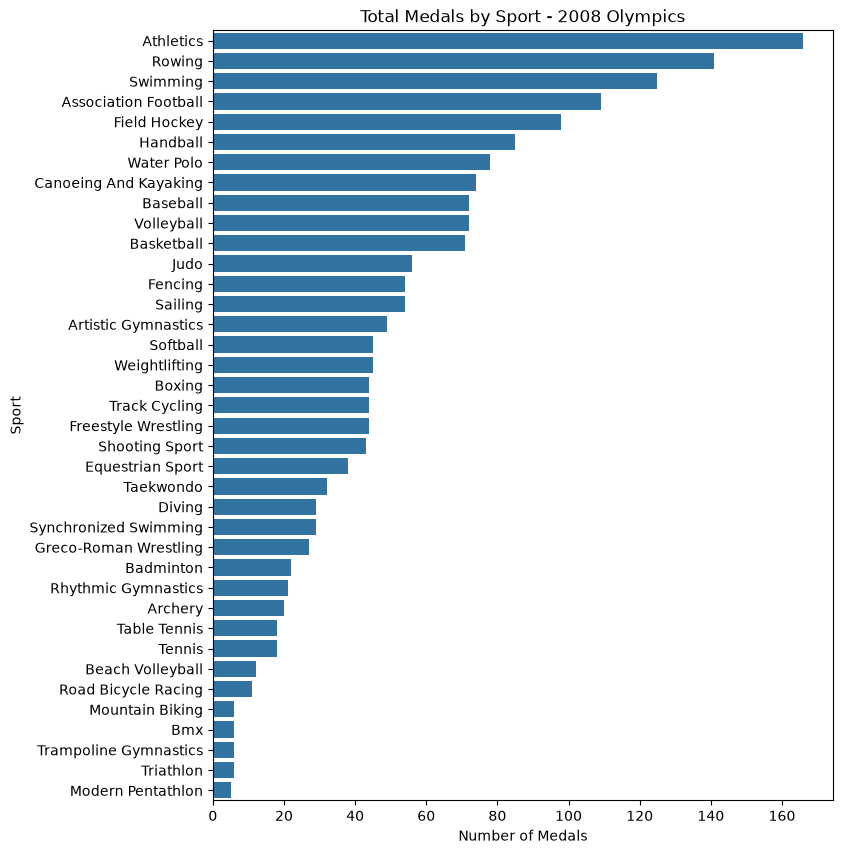

In [46]:
plt.figure(figsize=(8,10))
sns.countplot(data=df_long, y="sport", order=df_long["sport"].value_counts().index)
plt.xlabel("Number of Medals")
plt.title("Total Medals by Sport - 2008 Olympics")
plt.ylabel("Sport") 
plt.show()

The second chart I made is a countplot which shows total medals by gender in the 2008 Olympics. I chose this chart because it splits each medal into two genders marked by color and makes it into a vertical bar. I found that males won more medals than females in each medal category. This could be because there were more male events than female events in the 2008 Olympics.

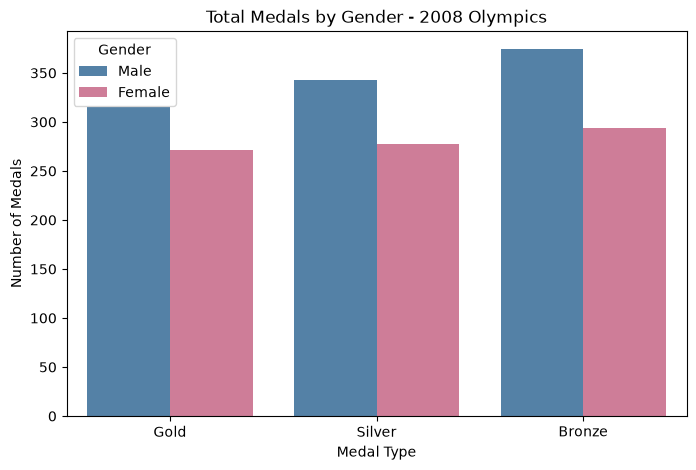

In [57]:
plt.figure(figsize=(8,5))
sns.countplot(data=df_long, x="medal", hue="gender", order=["Gold", "Silver", "Bronze"], palette={"Male": "steelblue", "Female": "palevioletred"})
plt.title("Total Medals by Gender - 2008 Olympics")
plt.xlabel("Medal Type")
plt.ylabel("Number of Medals")
plt.legend(title="Gender")
plt.show()